# Lab 13: Information Retrieval for RAG

## 1. What is Information Retrieval?

**Information retrieval (IR)** means finding relevant information from a collection of documents based on a user query.

**Example:** A student asks, *"How do transformers process words?"* The retrieval system searches course notes and returns the most relevant passages.

**Simple process:**

`Documents → Numerical representation → Compare with query → Rank → Top results`

## 2. Create a small document collection

Imagine these are short notes taken from an NLP course. Each string represents one document.

In [1]:
documents = [
    "Transformers use self-attention to understand relationships between words.",
    "TF-IDF represents documents using word importance scores.",
    "Word2Vec learns dense vector representations of words.",
    "Named entity recognition identifies names, places, and organizations in text.",
    "Information retrieval finds relevant documents for a user query.",
    "Cosine similarity measures how similar two text vectors are."]

for i, document in enumerate(documents):
    print(f"Document {i}: {document}")

Document 0: Transformers use self-attention to understand relationships between words.
Document 1: TF-IDF represents documents using word importance scores.
Document 2: Word2Vec learns dense vector representations of words.
Document 3: Named entity recognition identifies names, places, and organizations in text.
Document 4: Information retrieval finds relevant documents for a user query.
Document 5: Cosine similarity measures how similar two text vectors are.


## 3. Convert documents into TF-IDF vectors (sparse retrieval)

A computer cannot compare raw text directly using vector similarity. **TF-IDF** converts each document into a numerical vector.

- **TF** measures how frequently a word occurs in a document.
- **IDF** gives more importance to words that appear in fewer documents.

TF-IDF is a form of **sparse retrieval**: most word positions in the vectors are zero.

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(stop_words="english")
document_vectors = vectorizer.fit_transform(documents)

print("TF-IDF matrix shape:", document_vectors.shape)
print("First document vector:", document_vectors[0].toarray().round(2))

TF-IDF matrix shape: (6, 39)
First document vector: [[0.39 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.39 0.   0.   0.   0.   0.   0.39 0.   0.   0.
  0.   0.39 0.39 0.39 0.   0.   0.   0.   0.   0.   0.32]]


**Check:** The matrix has one row per document and one column per vocabulary word. A zero means that word has no TF-IDF weight in that document.

## 4. Search using a query

We use the **same TF-IDF vectorizer** to represent the user's query. Then we calculate **cosine similarity** between the query and every document.

- Higher similarity → more relevant according to TF-IDF.
- A similarity of 0 means the vectors do not share weighted terms.

In [3]:
from sklearn.metrics.pairwise import cosine_similarity

query = "How do transformers understand words?"
query_vector = vectorizer.transform([query])
scores = cosine_similarity(query_vector, document_vectors)[0]

for i, score in enumerate(scores):
    print(f"Document {i}: {score:.3f}")

Document 0: 0.633
Document 1: 0.000
Document 2: 0.173
Document 3: 0.000
Document 4: 0.000
Document 5: 0.000


## 5. Retrieve the top-k documents

Rather than reading every document, the system returns the **k** documents with the highest similarity scores.

In [4]:
k = 3
ranked_ids = scores.argsort()[::-1][:k]

for rank, i in enumerate(ranked_ids, start=1):
    print(f"Rank {rank} | Score: {scores[i]:.3f}")
    print(documents[i])
    print()

Rank 1 | Score: 0.633
Transformers use self-attention to understand relationships between words.

Rank 2 | Score: 0.173
Word2Vec learns dense vector representations of words.

Rank 3 | Score: 0.000
Information retrieval finds relevant documents for a user query.



## 6. Student exercises

**Exercise 1 — Change the query**  
Use `search()` to find notes about **named entity recognition**. Which document is ranked first?

**Exercise 2 — Change k**  
Search for `"document representation"` using `k=1` and then `k=3`. What changes?


### Solutions
First define the `search()` function used by the exercises.

In [5]:
import pandas as pd

def search(query, k=2):
    query_vector = vectorizer.transform([query])
    scores = cosine_similarity(query_vector, document_vectors)[0]
    top_ids = scores.argsort()[::-1][:k]
    results = pd.DataFrame({
        "Rank": range(1, len(top_ids) + 1),
        "Doc ID": top_ids,
        "Score": scores[top_ids].round(3),
        "Document": [documents[i] for i in top_ids]})
    return results.set_index("Rank")

**Exercise 1 — named entity recognition**

In [6]:
search("named entity recognition", k=3)

,Doc ID,Score,Document
Rank,,,
1,3,0.625,"Named entity recognition identifies names, pla..."
2,5,0.000,Cosine similarity measures how similar two tex...
3,4,0.000,Information retrieval finds relevant documents...


**Answer:** Document 3 (*"Named entity recognition identifies names, places, and organizations in text."*) is ranked first — it is the only document containing the terms *named*, *entity* and *recognition*; the other documents score 0.

**Exercise 2 — `"document representation"` with k=1 vs k=3**

In [7]:
print("k = 1"); display(search("document representation", k=1))
print("k = 3"); display(search("document representation", k=3))

k = 1


,Doc ID,Score,Document
Rank,,,
1,5,0.0,Cosine similarity measures how similar two tex...


k = 3


,Doc ID,Score,Document
Rank,,,
1,5,0.0,Cosine similarity measures how similar two tex...
2,4,0.0,Information retrieval finds relevant documents...
3,3,0.0,"Named entity recognition identifies names, pla..."


**Answer:** Every document scores **0.000** for this query. TF-IDF matches exact tokens and does no stemming, so *document* ≠ *documents* and *representation* ≠ *representations*/*represents*. Because all scores tie at 0, the ranking is arbitrary (argsort order).

- With `k=1` we get one (irrelevant) document; with `k=3` we get three. **Changing k only changes how many results are returned — it never changes the scores or their order.**
- This shows a real weakness of sparse retrieval: the relevant notes (Doc 1 on TF-IDF document representation and Doc 2 on Word2Vec vector representations) are missed because of word-form mismatches. Stemming/lemmatisation or dense embeddings would fix this, and filtering out zero-score results (Part 2) prevents passing junk context to a RAG model.

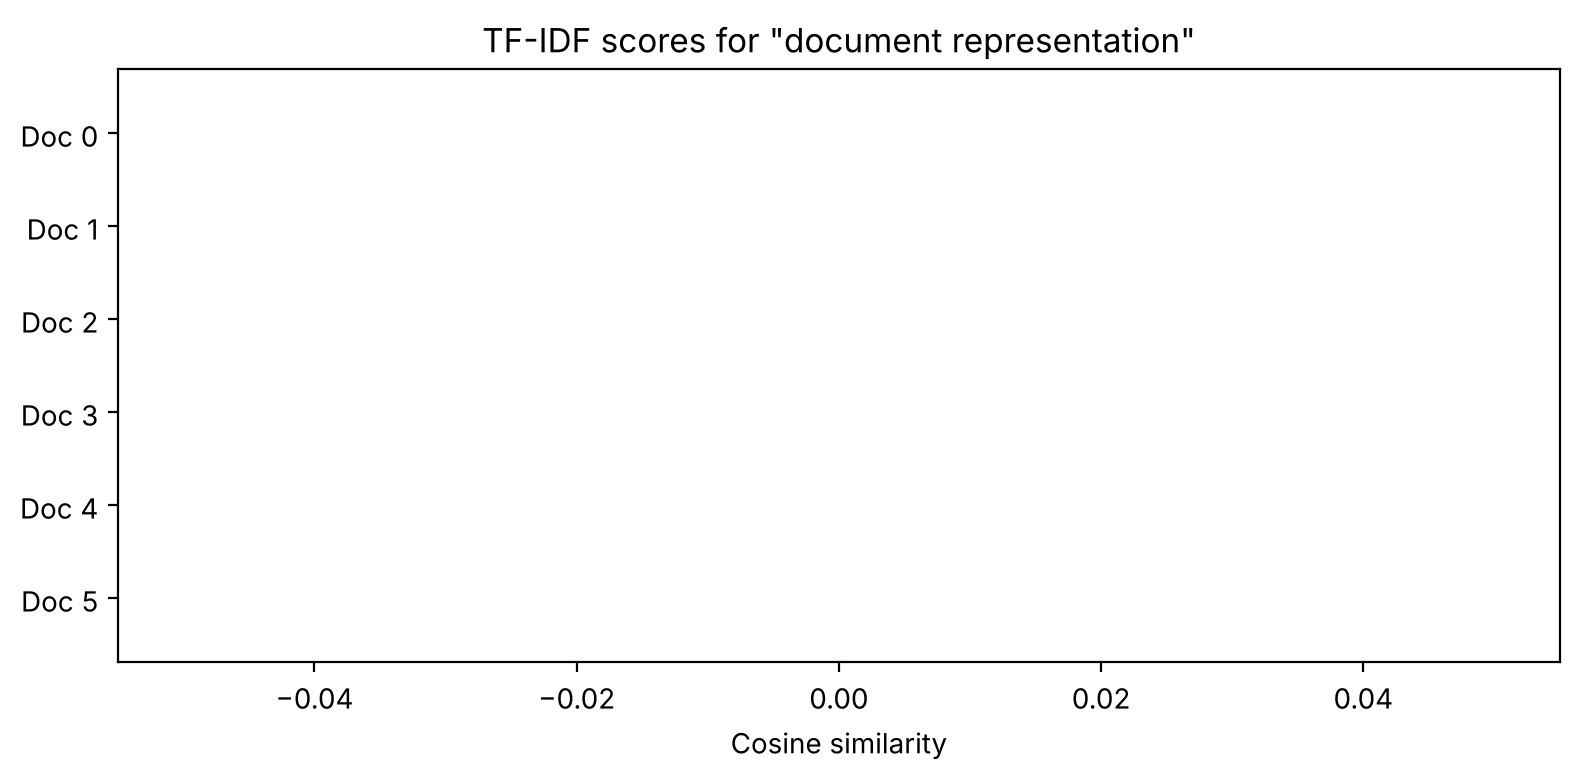

In [8]:
import matplotlib.pyplot as plt
q = "document representation"
s = cosine_similarity(vectorizer.transform([q]), document_vectors)[0]
plt.figure(figsize=(8,4))
plt.barh([f"Doc {i}" for i in range(len(documents))], s, color="steelblue")
plt.gca().invert_yaxis(); plt.xlabel("Cosine similarity"); plt.title(f'TF-IDF scores for "{q}"')
plt.tight_layout(); plt.show()

## Summary

You built a small **information retrieval** system using TF-IDF and cosine similarity. It converts documents and queries into vectors, ranks documents by relevance, and returns the top results.

**Connection to RAG:** These retrieved documents can later be passed to a language model as supporting context for answer generation.